# Data Preparation

## Import Library & Dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("data_marketing_growth_analytics.xlsx")

display(df.head())
df.info()

,user_id,first_visit_date,channel,source,device,sessions,page_views,bounce,add_to_cart,purchase,revenue,ad_cost,clicks,impressions,repeat_purchase,retention_month
0,1,2025-02-17,Referral,instagram,Mobile,7,4,0,1,1,401318,0,40,880,0,2
1,2,2025-01-05,Referral,facebook,Mobile,3,5,0,0,0,0,0,12,264,0,0
2,3,2025-01-26,Referral,tiktok,Mobile,4,5,0,0,0,0,0,3,72,0,0
3,4,2025-02-24,Paid Ads,facebook,Mobile,4,2,0,1,0,0,18215,16,320,0,0
4,5,2025-01-04,Referral,instagram,Mobile,1,18,0,0,0,0,0,44,792,0,0


<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           800 non-null    int64         
 1   first_visit_date  800 non-null    datetime64[us]
 2   channel           800 non-null    str           
 3   source            800 non-null    str           
 4   device            800 non-null    str           
 5   sessions          800 non-null    int64         
 6   page_views        800 non-null    int64         
 7   bounce            800 non-null    int64         
 8   add_to_cart       800 non-null    int64         
 9   purchase          800 non-null    int64         
 10  revenue           800 non-null    int64         
 11  ad_cost           800 non-null    int64         
 12  clicks            800 non-null    int64         
 13  impressions       800 non-null    int64         
 14  repeat_purchase   800 non-null    int

## Data Understanding

In [3]:
# Statistik deskriptif
display(df.describe(include="all").T)

# Missing values
display(df.isnull().sum())

# Duplicate rows
print("Duplicates:", df.duplicated().sum())

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
user_id,800.0,NaN,NaN,NaN,400.5,1.0,200.75,400.5,600.25,800.0,231.0844
first_visit_date,800,NaN,NaN,NaN,2025-01-30 23:45:36,2025-01-01 00:00:00,2025-01-16 00:00:00,2025-01-31 00:00:00,2025-02-15 00:00:00,2025-03-01 00:00:00,NaN
channel,800,5,Paid Ads,251,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source,800,6,instagram,143,NaN,NaN,NaN,NaN,NaN,NaN,NaN
device,800,3,Mobile,504,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sessions,800.0,NaN,NaN,NaN,4.13125,1.0,3.0,4.0,6.0,7.0,1.970121
page_views,800.0,NaN,NaN,NaN,10.05375,1.0,5.0,10.0,15.0,19.0,5.482329
bounce,800.0,NaN,NaN,NaN,0.0325,0.0,0.0,0.0,0.0,1.0,0.177435
add_to_cart,800.0,NaN,NaN,NaN,0.41125,0.0,0.0,0.0,1.0,1.0,0.492368
purchase,800.0,NaN,NaN,NaN,0.1875,0.0,0.0,0.0,0.0,1.0,0.390557


user_id             0
first_visit_date    0
channel             0
source              0
device              0
sessions            0
page_views          0
bounce              0
add_to_cart         0
purchase            0
revenue             0
ad_cost             0
clicks              0
impressions         0
repeat_purchase     0
retention_month     0
dtype: int64

Duplicates: 0


## Data Cleaning

In [4]:
# Check duplicate user_id
print("Duplicate User ID:", df["user_id"].duplicated().sum())

# Check categorical unique values
for col in ["channel", "source", "device"]:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))

Duplicate User ID: 0

channel
channel
Paid Ads          251
Organic Search    198
Social Media      151
Email             125
Referral           75
Name: count, dtype: int64

source
source
instagram    143
google       138
facebook     132
tiktok       130
email        130
direct       127
Name: count, dtype: int64

device
device
Mobile     504
Desktop    262
Tablet      34
Name: count, dtype: int64


## Validasi Data Numerik

In [5]:
# Check negative values
numeric_cols = df.select_dtypes(include="number").columns.drop("user_id")

print("Negative Values:")
print((df[numeric_cols] < 0).sum())

# Check binary columns
for col in ["bounce", "add_to_cart", "purchase", "repeat_purchase"]:
    print(f"\n{col}")
    print(df[col].value_counts())

# Check logical consistency
print("\nPurchase without Add to Cart:",
      ((df["purchase"] == 1) & (df["add_to_cart"] == 0)).sum())

print("\nRepeat Purchase without Purchase:",
      ((df["repeat_purchase"] == 1) & (df["purchase"] == 0)).sum())

print("\nRevenue without Purchase:",
      ((df["revenue"] > 0) & (df["purchase"] == 0)).sum())

print("\nClicks greater than Impressions:",
      (df["clicks"] > df["impressions"]).sum())

Negative Values:
sessions           0
page_views         0
bounce             0
add_to_cart        0
purchase           0
revenue            0
ad_cost            0
clicks             0
impressions        0
repeat_purchase    0
retention_month    0
dtype: int64

bounce
bounce
0    774
1     26
Name: count, dtype: int64

add_to_cart
add_to_cart
0    471
1    329
Name: count, dtype: int64

purchase
purchase
0    650
1    150
Name: count, dtype: int64

repeat_purchase
repeat_purchase
0    752
1     48
Name: count, dtype: int64

Purchase without Add to Cart: 0

Repeat Purchase without Purchase: 0

Revenue without Purchase: 0

Clicks greater than Impressions: 0


## Outlier Detection with IQR

In [6]:
# Numerical columns for outlier detection
outlier_cols = [
    "sessions",
    "page_views",
    "revenue",
    "ad_cost",
    "clicks",
    "impressions",
    "retention_month"
]

outlier_results = []

for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    outlier_results.append({
        "Column": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": len(outliers),
        "Outlier %": round(len(outliers) / len(df) * 100, 2)
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)

,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,sessions,3.00,6.00,3.00,-1.500,10.500,0,0.00
1,page_views,5.00,15.00,10.00,-10.000,30.000,0,0.00
2,revenue,0.00,0.00,0.00,0.000,0.000,150,18.75
3,ad_cost,0.00,21996.75,21996.75,-32995.125,54991.875,89,11.12
4,clicks,11.00,37.00,26.00,-28.000,76.000,0,0.00
5,impressions,208.75,812.00,603.25,-696.125,1716.875,7,0.88
6,retention_month,0.00,0.00,0.00,0.000,0.000,150,18.75


## Investigasi Outliers

In [7]:
# Investigate Ad Cost Outliers
high_ad_cost = df[df["ad_cost"] > 54991.875]

display(
    high_ad_cost.groupby("channel").agg(
        users=("user_id", "count"),
        total_ad_cost=("ad_cost", "sum"),
        avg_ad_cost=("ad_cost", "mean"),
        total_revenue=("revenue", "sum")
    ).round(2)
)

,users,total_ad_cost,avg_ad_cost,total_revenue
channel,,,,
Paid Ads,89,5945983,66808.8,5687093


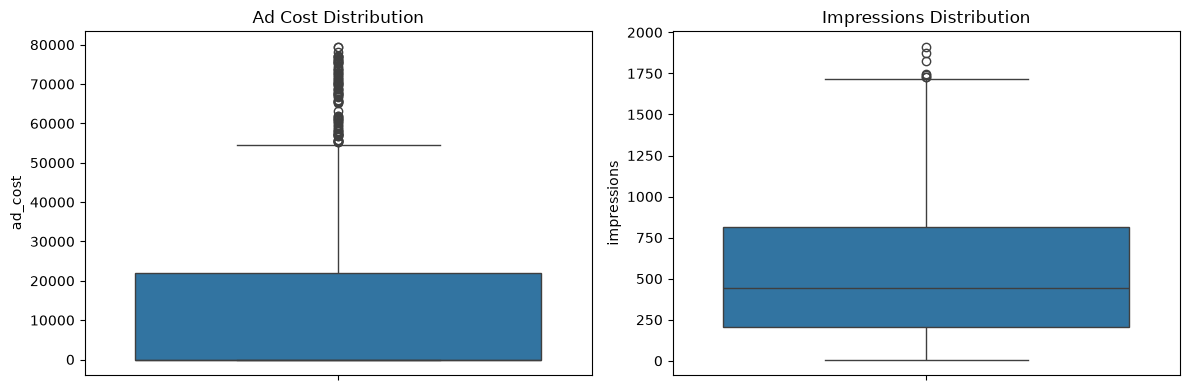

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(y=df["ad_cost"], ax=axes[0])
axes[0].set_title("Ad Cost Distribution")

sns.boxplot(y=df["impressions"], ax=axes[1])
axes[1].set_title("Impressions Distribution")

plt.tight_layout()
plt.show()

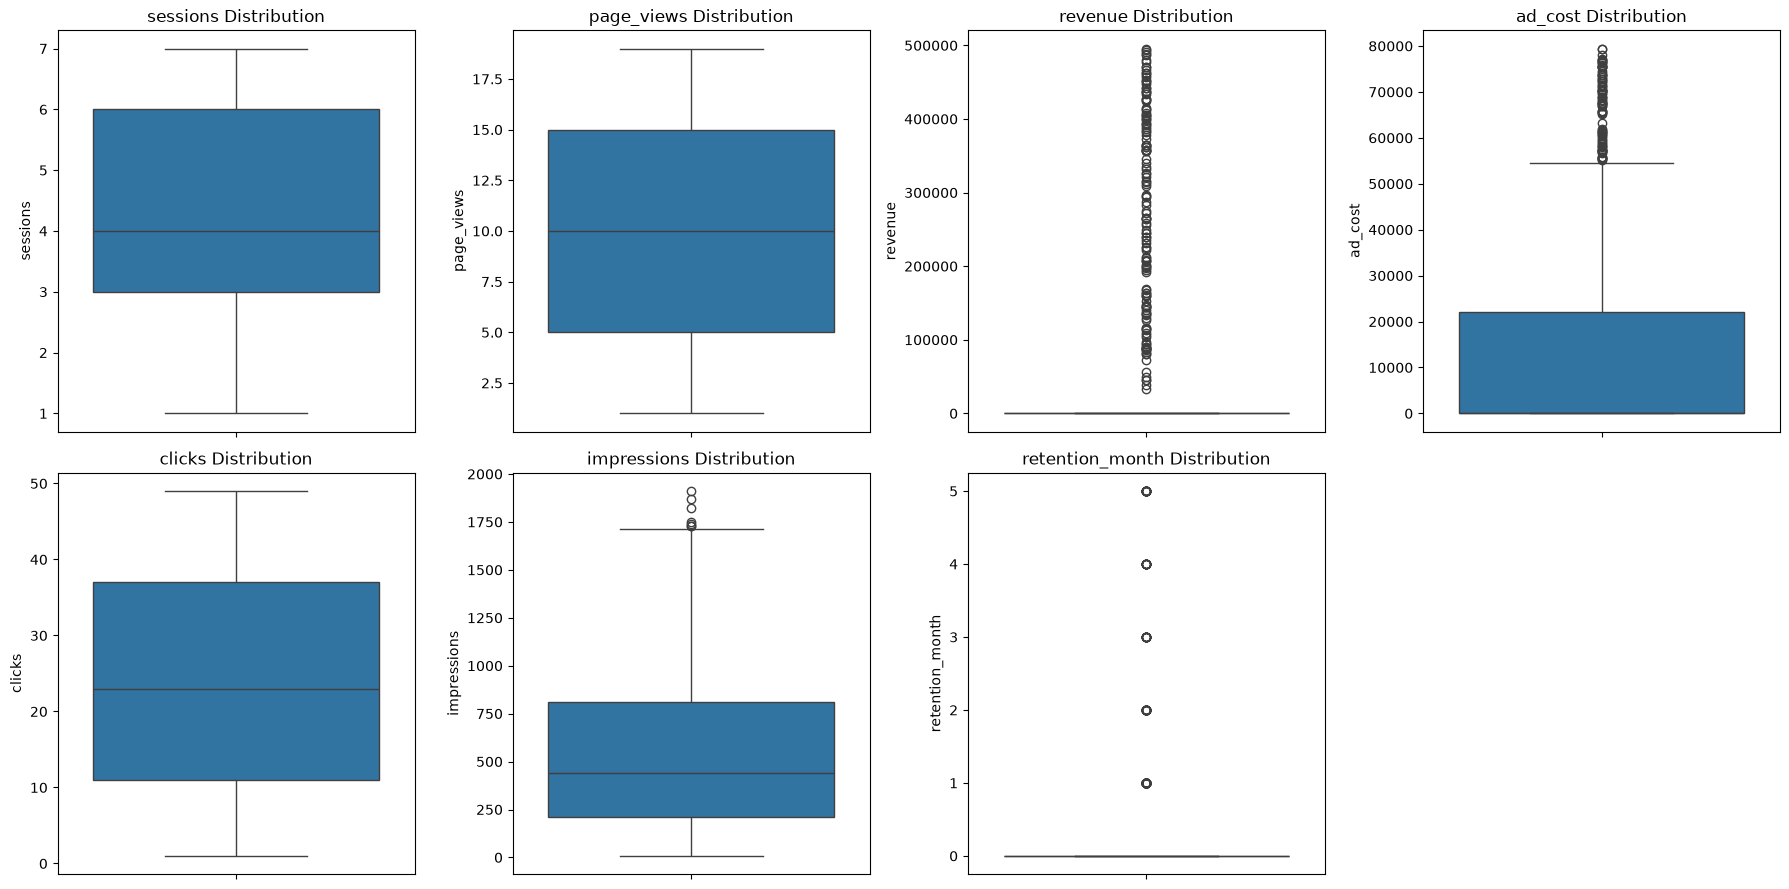

In [9]:
outlier_cols = [
    "sessions",
    "page_views",
    "revenue",
    "ad_cost",
    "clicks",
    "impressions",
    "retention_month"
]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for i, col in enumerate(outlier_cols):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(f"{col} Distribution")
    axes[i].set_ylabel(col)

# Remove unused subplot
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

## Feature Engineering

In [11]:
# Create a clean copy
df_clean = df.copy()

# Date features
df_clean["year"] = df_clean["first_visit_date"].dt.year
df_clean["month"] = df_clean["first_visit_date"].dt.month
df_clean["year_month"] = df_clean["first_visit_date"].dt.to_period("M").astype(str)

# Customer funnel status
df_clean["funnel_stage"] = np.select(
    [
        df_clean["purchase"] == 1,
        df_clean["add_to_cart"] == 1
    ],
    [
        "Purchased",
        "Added to Cart"
    ],
    default="No Cart"
)


In [12]:
# Paid acquisition flag
df_clean["is_paid_user"] = (
    df_clean["channel"] == "Paid Ads"
).astype(int)

display(df_clean.head())

,user_id,first_visit_date,channel,source,device,sessions,page_views,bounce,add_to_cart,purchase,...,ad_cost,clicks,impressions,repeat_purchase,retention_month,year,month,year_month,funnel_stage,is_paid_user
0,1,2025-02-17,Referral,instagram,Mobile,7,4,0,1,1,...,0,40,880,0,2,2025,2,2025-02,Purchased,0
1,2,2025-01-05,Referral,facebook,Mobile,3,5,0,0,0,...,0,12,264,0,0,2025,1,2025-01,No Cart,0
2,3,2025-01-26,Referral,tiktok,Mobile,4,5,0,0,0,...,0,3,72,0,0,2025,1,2025-01,No Cart,0
3,4,2025-02-24,Paid Ads,facebook,Mobile,4,2,0,1,0,...,18215,16,320,0,0,2025,2,2025-02,Added to Cart,1
4,5,2025-01-04,Referral,instagram,Mobile,1,18,0,0,0,...,0,44,792,0,0,2025,1,2025-01,No Cart,0


In [13]:
# Check new features
print("Dataset Shape:", df_clean.shape)

print("\nYear-Month Distribution:")
print(df_clean["year_month"].value_counts().sort_index())

print("\nFunnel Stage Distribution:")
print(df_clean["funnel_stage"].value_counts())

print("\nPaid User Distribution:")
print(df_clean["is_paid_user"].value_counts())

Dataset Shape: (800, 21)

Year-Month Distribution:
year_month
2025-01    403
2025-02    384
2025-03     13
Name: count, dtype: int64

Funnel Stage Distribution:
funnel_stage
No Cart          471
Added to Cart    179
Purchased        150
Name: count, dtype: int64

Paid User Distribution:
is_paid_user
0    549
1    251
Name: count, dtype: int64


# Exploratory Data Analysis (EDA)

## Univariate Analysis

### Numerical Distribution

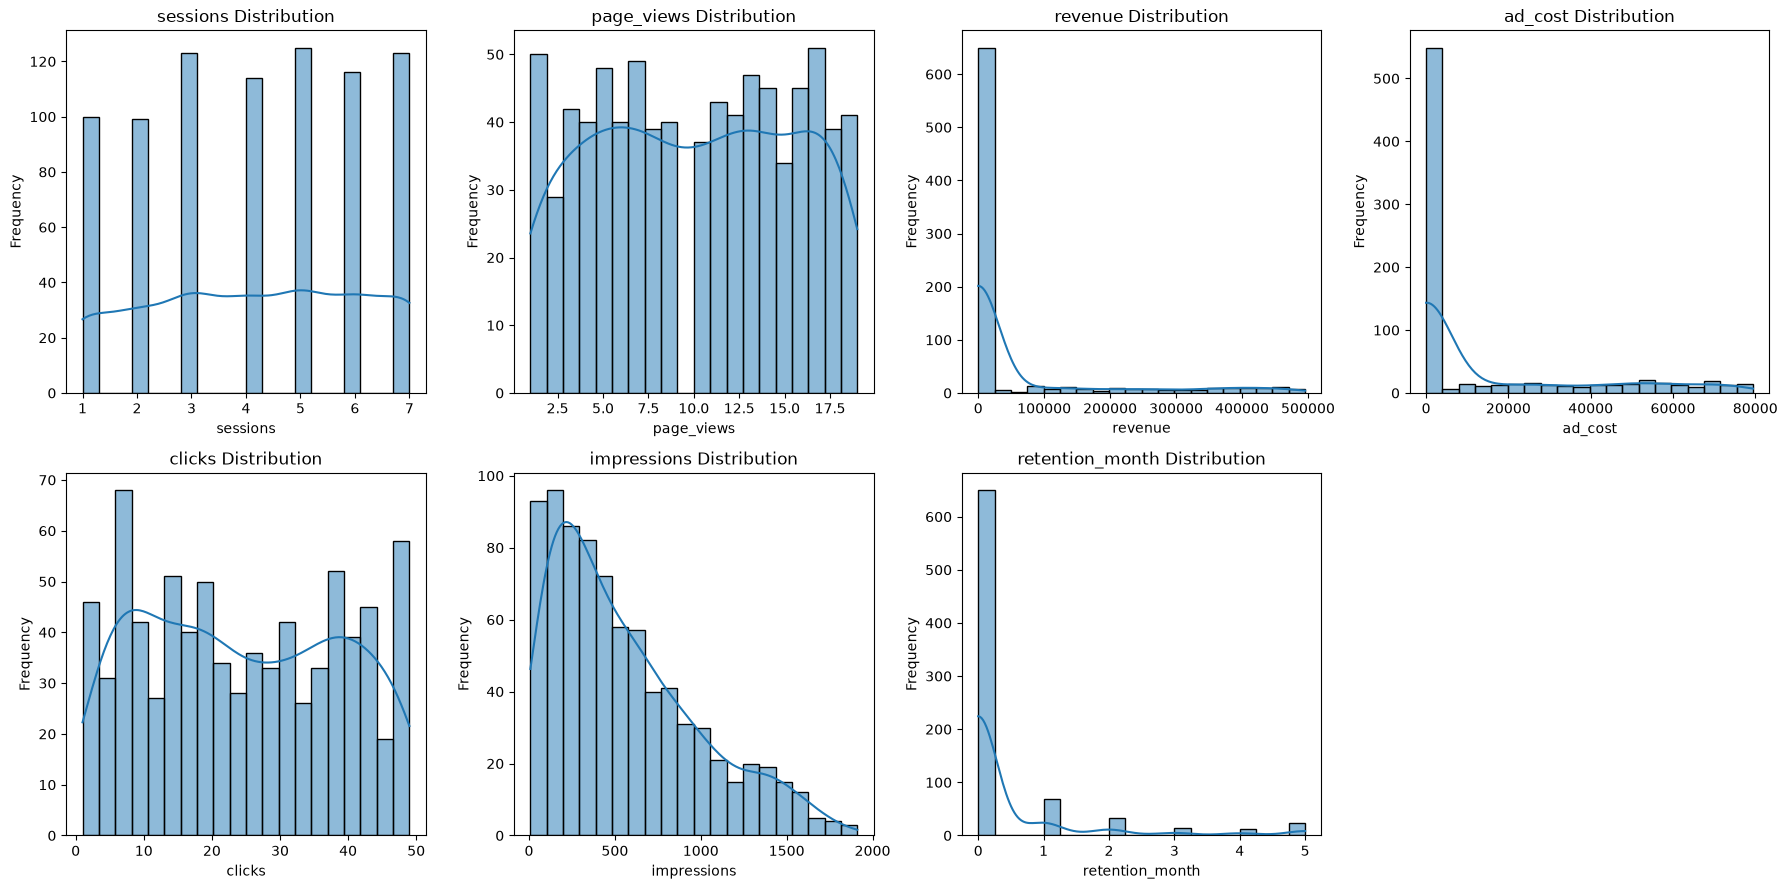

In [22]:
# Select numerical variables
numerical_cols = [
    "sessions",
    "page_views",
    "revenue",
    "ad_cost",
    "clicks",
    "impressions",
    "retention_month"
]

# Create histograms
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.histplot(
        data=df_clean,
        x=col,
        bins=20,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f"{col} Distribution")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

# Remove empty subplot
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

### Skewness Analysis

In [24]:
# Calculate skewness
skewness = df_clean[numerical_cols].skew()

skew_summary = pd.DataFrame({
    "Variable": skewness.index,
    "Skewness": skewness.values
})

# Classify skewness
def classify_skew(value):
    if value > 1:
        return "Highly Right Skewed"
    elif value > 0.5:
        return "Moderately Right Skewed"
    elif value < -1:
        return "Highly Left Skewed"
    elif value < -0.5:
        return "Moderately Left Skewed"
    else:
        return "Approximately Symmetric"

skew_summary["Distribution"] = (
    skew_summary["Skewness"].apply(classify_skew)
)

display(skew_summary.round(3))

,Variable,Skewness,Distribution
0,sessions,-0.076,Approximately Symmetric
1,page_views,-0.020,Approximately Symmetric
2,revenue,2.342,Highly Right Skewed
3,ad_cost,1.477,Highly Right Skewed
4,clicks,0.098,Approximately Symmetric
5,impressions,0.902,Moderately Right Skewed
6,retention_month,2.980,Highly Right Skewed


Distribusi Numerik — Key Findings
Analisis distribusi numerik menunjukkan beberapa karakteristik penting dalam dataset:
1. Sessions, Page Views, dan Clicks memiliki distribusi yang relatif simetris, menunjukkan bahwa nilai data cukup seimbang tanpa adanya skewness yang signifikan.
2. Revenue memiliki distribusi yang sangat menceng ke kanan (right-skewed) dengan nilai skewness sebesar 2,342. Hal ini menunjukkan bahwa sebagian besar pengguna tidak melakukan pembelian, sementara sebagian kecil pengguna menghasilkan pendapatan yang tinggi.
3. Ad Cost memiliki distribusi yang sangat menceng ke kanan dengan nilai skewness sebesar 1,477. Kondisi ini terutama disebabkan oleh biaya iklan yang hanya tercatat pada channel Paid Ads.
4. Impressions memiliki distribusi yang cukup menceng ke kanan (moderate positive skewness) dengan nilai skewness sebesar 0,902. Hal ini menunjukkan bahwa sebagian kecil observasi memperoleh jumlah tayangan iklan yang jauh lebih tinggi dibandingkan observasi lainnya.
5. Retention Month memiliki nilai skewness tertinggi, yaitu 2,980. Hal ini mengindikasikan bahwa sebagian besar pengguna memiliki nilai retention month sebesar nol, sementara hanya sebagian kecil pengguna yang memiliki durasi retensi lebih panjang.
Kesimpulan
Dataset memiliki beberapa variabel dengan dominasi nilai nol (zero-heavy) dan distribusi yang right-skewed.

### Categorical Distribution

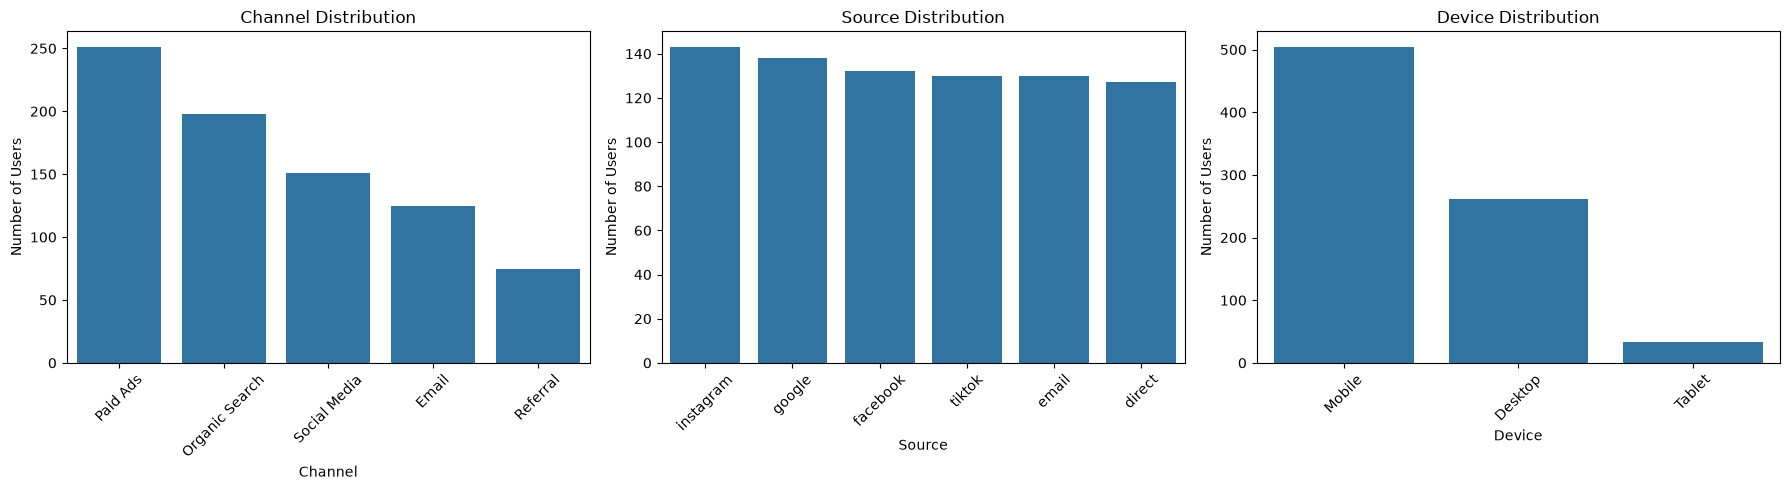

In [25]:
categorical_cols = ["channel", "source", "device"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(categorical_cols):
    order = df_clean[col].value_counts().index

    sns.countplot(
        data=df_clean,
        x=col,
        order=order,
        ax=axes[i]
    )

    axes[i].set_title(f"{col.title()} Distribution")
    axes[i].set_xlabel(col.title())
    axes[i].set_ylabel("Number of Users")
    axes[i].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

Distribusi Kategorikal — Key Findings
1. Marketing Channel: Paid Ads memberikan kontribusi jumlah pengguna terbesar, yaitu 31,38%, diikuti oleh Organic Search sebesar 24,75%. Hal ini menunjukkan bahwa akuisisi pengguna melalui iklan berbayar merupakan channel dengan kontribusi individu terbesar dalam dataset.
2. Traffic Source: Instagram memiliki jumlah pengguna tertinggi, yaitu 143 pengguna. Meskipun demikian, distribusi traffic relatif merata di antara keenam sumber traffic yang tersedia.
3. Device Distribution: Mobile mendominasi akses pengguna dengan kontribusi sebesar 63%. Hal ini menunjukkan bahwa pengalaman pengguna pada perangkat mobile perlu menjadi perhatian utama dalam strategi pemasaran dan optimalisasi konversi.

Kesimpulan

Akuisisi pengguna didominasi oleh Paid Ads, sementara Mobile menjadi perangkat yang paling banyak digunakan.

## Bivariate Analysis

### Numerical Correlation Analysis

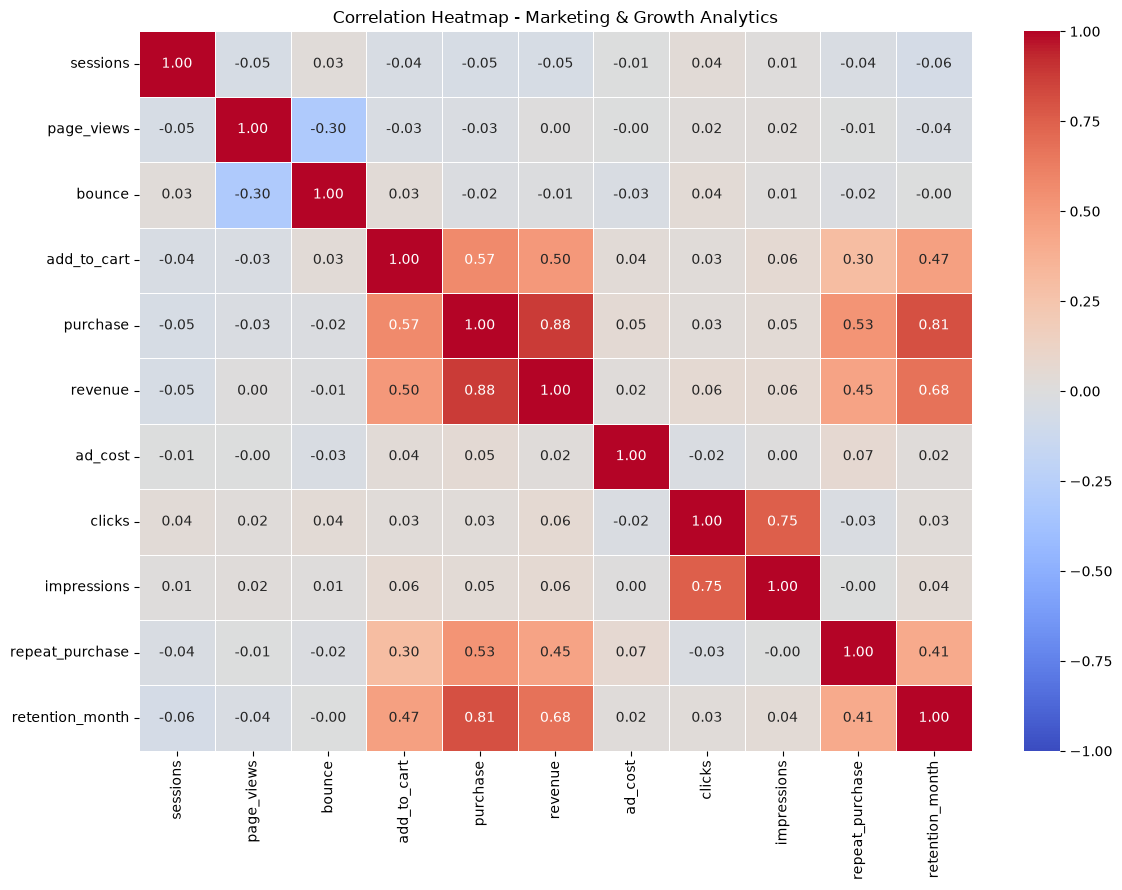

In [28]:
# Select numerical variables
corr_cols = [
    "sessions",
    "page_views",
    "bounce",
    "add_to_cart",
    "purchase",
    "revenue",
    "ad_cost",
    "clicks",
    "impressions",
    "repeat_purchase",
    "retention_month"
]

# Calculate Pearson correlation
corr_matrix = df_clean[corr_cols].corr(method="pearson")

# Visualize correlation heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Correlation Heatmap - Marketing & Growth Analytics")
plt.tight_layout()
plt.show()

Analisis Korelasi — Temuan Utama (Key Findings)
1. Purchase dan Revenue (r = 0,88): Memiliki korelasi positif yang sangat kuat, menunjukkan bahwa pengguna yang melakukan pembelian cenderung menghasilkan pendapatan lebih tinggi. Hal ini sejalan dengan struktur transaksi dalam dataset.
2. Purchase dan Retention Month (r = 0,81): Menunjukkan hubungan positif yang sangat kuat antara aktivitas pembelian dan durasi retensi pengguna. Namun, definisi dan metode pengukuran retention dalam dataset masih perlu divalidasi lebih lanjut.
3. Clicks dan Impressions (r = 0,75): Memiliki korelasi positif yang kuat, menunjukkan bahwa semakin tinggi jumlah tayangan iklan (impressions), semakin tinggi pula jumlah klik yang diperoleh. Hal ini mengindikasikan adanya hubungan positif antara eksposur iklan dan interaksi pengguna.
4. Add to Cart dan Purchase (r = 0,57): Memiliki korelasi positif sedang, yang menunjukkan pentingnya tahap penambahan produk ke keranjang (add to cart) dalam proses konversi pelanggan (conversion funnel).
5. Ad Cost dan Revenue (r = 0,02): Hampir tidak menunjukkan hubungan linear pada tingkat observasi individu. Oleh karena itu, diperlukan analisis lebih lanjut berdasarkan masing-masing marketing channel untuk mengevaluasi efisiensi pengeluaran iklan terhadap pendapatan yang dihasilkan.
6. Page Views dan Bounce (r = -0,30): Memiliki korelasi negatif sedang, yang menunjukkan bahwa semakin tinggi jumlah halaman yang dilihat pengguna, semakin rendah kecenderungan terjadinya bounce.

Kesimpulan

Variabel yang berkaitan dengan Purchase menunjukkan hubungan positif paling kuat dengan Revenue dan Retention Month. Hal ini mengindikasikan bahwa aktivitas pembelian memiliki keterkaitan yang erat dengan pendapatan serta retensi pengguna.

### Ad Cost vs Revenue Analysis

Text(0.5, 0, 'Advertising Cost')

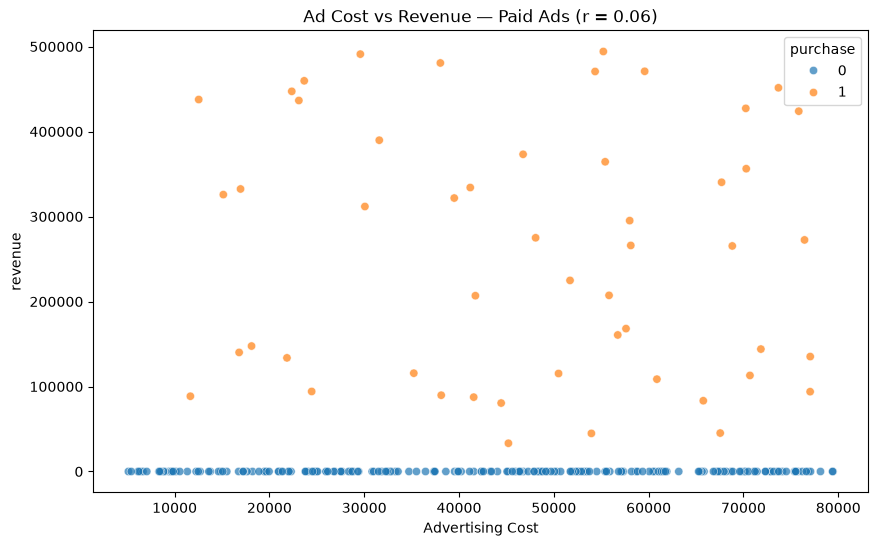

In [29]:
# Filter Paid Ads only
paid_ads = df_clean[df_clean["channel"] == "Paid Ads"].copy()

# Calculate correlation
correlation = paid_ads["ad_cost"].corr(paid_ads["revenue"])

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=paid_ads,
    x="ad_cost",
    y="revenue",
    hue="purchase",
    alpha=0.7
)

plt.title(
    f"Ad Cost vs Revenue — Paid Ads (r = {correlation:.2f})"
)

plt.xlabel("Advertising Cost")

Ad Cost vs Revenue — Key Findings

Analisis scatter plot menunjukkan adanya korelasi positif yang sangat lemah antara biaya iklan (Ad Cost) dan pendapatan (Revenue) pada pengguna yang berasal dari channel Paid Ads, dengan nilai korelasi sebesar r = 0,06.

Pengguna yang menghasilkan pendapatan tersebar pada berbagai tingkat biaya iklan. Sementara itu, masih terdapat banyak pengguna yang tidak menghasilkan pendapatan meskipun telah mengeluarkan biaya iklan.

Hal ini menunjukkan bahwa peningkatan biaya iklan per pengguna tidak memiliki hubungan yang kuat dengan peningkatan pendapatan per pengguna dalam dataset yang dianalisis.

Kesimpulan

Biaya iklan (Ad Cost) saja tidak cukup untuk menjelaskan variasi pendapatan (Revenue) yang dihasilkan dari channel Paid Ads.

Oleh karena itu, diperlukan analisis lebih lanjut terhadap beberapa indikator utama, yaitu Conversion Rate, Cost per Purchasing User, dan Return on 
Ad Spend (ROAS) untuk mengevaluasi efektivitas strategi iklan berbayar.

Analisis tersebut dapat membantu mengidentifikasi peluang optimalisasi anggaran pemasaran, meningkatkan efisiensi biaya akuisisi pelanggan, serta memaksimalkan pendapatan dari aktivitas periklanan.

### Sessions vs Page Views

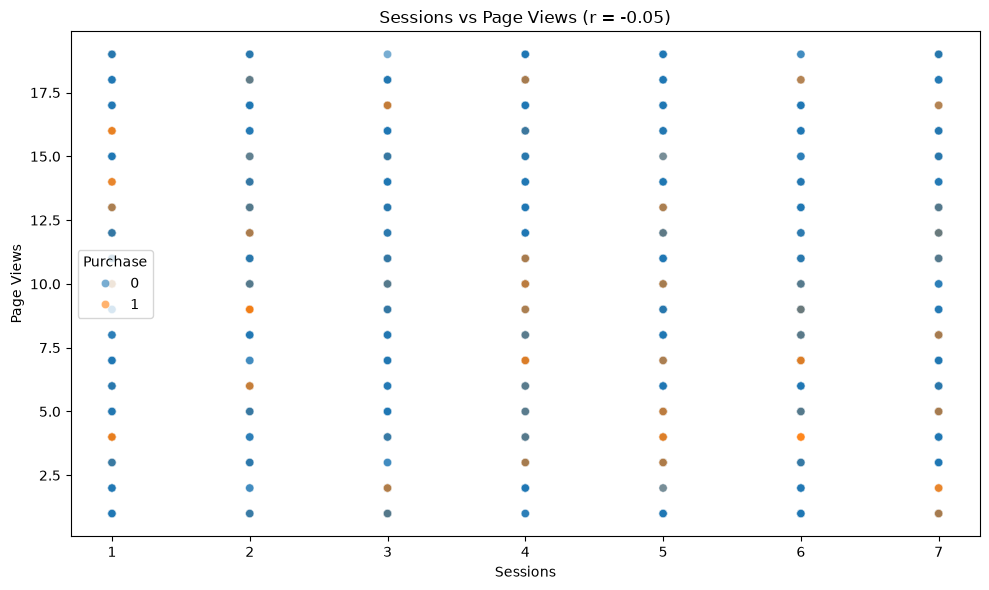

Correlation: -0.054


In [31]:
# Calculate correlation
correlation = df_clean["sessions"].corr(
    df_clean["page_views"]
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="sessions",
    y="page_views",
    hue="purchase",
    alpha=0.6
)

plt.title(
    f"Sessions vs Page Views (r = {correlation:.2f})"
)

plt.xlabel("Sessions")
plt.ylabel("Page Views")
plt.legend(title="Purchase")
plt.tight_layout()
plt.show()

print(f"Correlation: {correlation:.3f}")

Sessions vs Page Views — Temuan Utama (Key Findings)

Analisis scatter plot menunjukkan adanya korelasi negatif yang sangat lemah antara jumlah sesi (Sessions) dan jumlah halaman yang dilihat (Page Views), dengan nilai korelasi sebesar r = -0,054.

Pengguna dengan jumlah sesi yang lebih tinggi tidak selalu menghasilkan jumlah page views yang lebih banyak. Jumlah page views menunjukkan variasi yang cukup besar pada berbagai tingkat sessions.

Selain itu, pengguna yang melakukan pembelian (Purchasing Users) maupun yang tidak melakukan pembelian (Non-Purchasing Users) tersebar pada berbagai kombinasi sessions dan page views, tanpa adanya pola pemisahan yang jelas.

Kesimpulan

Frekuensi kunjungan pengguna (Sessions) saja tidak dapat dijadikan indikator yang kuat untuk mengukur tingkat keterlibatan pengguna (User Engagement) maupun kecenderungan melakukan pembelian (Purchasing Behavior) dalam dataset ini.

Oleh karena itu, diperlukan analisis segmentasi lebih lanjut untuk memahami pola interaksi dan konversi pengguna, seperti membandingkan Page Views per Session, Conversion Rate, serta perilaku pengguna berdasarkan Marketing Channel dan Device.

Analisis tersebut dapat membantu mengidentifikasi karakteristik pengguna yang memiliki potensi konversi lebih tinggi serta mendukung optimalisasi strategi pemasaran dan pengalaman pengguna.

### Marketing Channel vs Revenue Analysis

In [33]:
# Aggregate revenue by marketing channel
channel_revenue = df_clean.groupby("channel").agg(
    total_users=("user_id", "nunique"),
    total_revenue=("revenue", "sum")
).reset_index()

# Calculate revenue per user
channel_revenue["revenue_per_user"] = (
    channel_revenue["total_revenue"] /
    channel_revenue["total_users"]
)

# Sort by total revenue
channel_revenue = channel_revenue.sort_values(
    "total_revenue", ascending=False
)

display(channel_revenue.round(2))

,channel,total_users,total_revenue,revenue_per_user
2,Paid Ads,251,13177258,52499.04
4,Social Media,151,10512961,69622.26
1,Organic Search,198,7972474,40265.02
0,Email,125,4894673,39157.38
3,Referral,75,4446539,59287.19


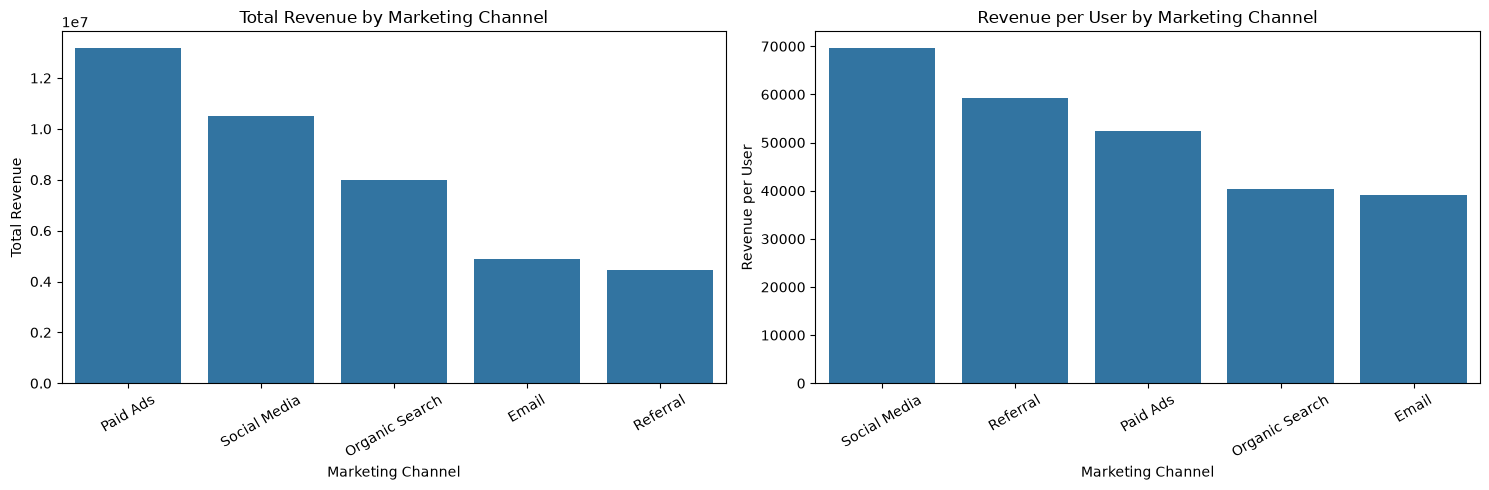

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Total Revenue
sns.barplot(
    data=channel_revenue,
    x="channel",
    y="total_revenue",
    ax=axes[0]
)

axes[0].set_title("Total Revenue by Marketing Channel")
axes[0].set_xlabel("Marketing Channel")
axes[0].set_ylabel("Total Revenue")
axes[0].tick_params(axis="x", rotation=30)

# Revenue per User
sns.barplot(
    data=channel_revenue.sort_values(
        "revenue_per_user", ascending=False
    ),
    x="channel",
    y="revenue_per_user",
    ax=axes[1]
)

axes[1].set_title("Revenue per User by Marketing Channel")
axes[1].set_xlabel("Marketing Channel")
axes[1].set_ylabel("Revenue per User")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

Marketing Channel vs Revenue — Key Findings

1. Paid Ads menghasilkan total pendapatan tertinggi, yaitu 13,18 juta, didukung oleh jumlah pengguna terbesar sebanyak 251 pengguna. Namun, pendapatan rata-rata per pengguna (Revenue per User) masih lebih rendah dibandingkan Social Media dan Referral.

2. Social Media memiliki Revenue per User tertinggi, yaitu 69.622, sekitar 32,6% lebih tinggi dibandingkan Paid Ads. Hal ini menunjukkan bahwa Social Media memiliki kemampuan menghasilkan pendapatan rata-rata per pengguna yang lebih tinggi.

3. Referral menempati posisi kedua dalam Revenue per User, yaitu 59.287, meskipun memiliki jumlah pengguna paling sedikit. Kondisi ini mengindikasikan adanya potensi pertumbuhan melalui optimalisasi channel Referral.

4. Organic Search dan Email menghasilkan Revenue per User yang relatif lebih rendah dibandingkan channel lainnya. Hal ini menunjukkan perlunya analisis lebih lanjut untuk mengidentifikasi perbedaan tingkat konversi (Conversion Rate) dan perilaku pembelian (Purchasing Behavior) pengguna pada kedua channel tersebut.

Kesimpulan

Paid Ads menjadi channel dengan kontribusi total pendapatan terbesar, sementara Social Media dan Referral menunjukkan kemampuan monetisasi pengguna yang lebih tinggi berdasarkan Revenue per User.

Hal ini menunjukkan bahwa jumlah pengguna yang besar tidak selalu menghasilkan efisiensi monetisasi yang lebih baik.

Oleh karena itu, efektivitas setiap marketing channel perlu dievaluasi berdasarkan dua aspek utama, yaitu volume akuisisi pengguna (User Acquisition Volume) dan efisiensi monetisasi (Monetization Efficiency), serta mempertimbangkan biaya akuisisi pelanggan (Customer Acquisition Cost/CAC) apabila data tersedia.

Analisis ini dapat menjadi dasar dalam menentukan strategi alokasi anggaran pemasaran yang lebih efektif, dengan mempertimbangkan keseimbangan antara pertumbuhan jumlah pengguna, pendapatan, dan efisiensi biaya.

### Device vs Conversion Rate

In [36]:
# Aggregate conversion metrics by device
device_conversion = df_clean.groupby("device").agg(
    total_users=("user_id", "nunique"),
    total_purchase=("purchase", "sum"),
    total_revenue=("revenue", "sum")
).reset_index()

# Calculate conversion rate
device_conversion["conversion_rate"] = (
    device_conversion["total_purchase"] /
    device_conversion["total_users"] * 100
)

# Sort by conversion rate
device_conversion = device_conversion.sort_values(
    "conversion_rate", ascending=False
)

display(device_conversion.round(2))

,device,total_users,total_purchase,total_revenue,conversion_rate
2,Tablet,34,7,2417270,20.59
1,Mobile,504,98,25988305,19.44
0,Desktop,262,45,12598330,17.18


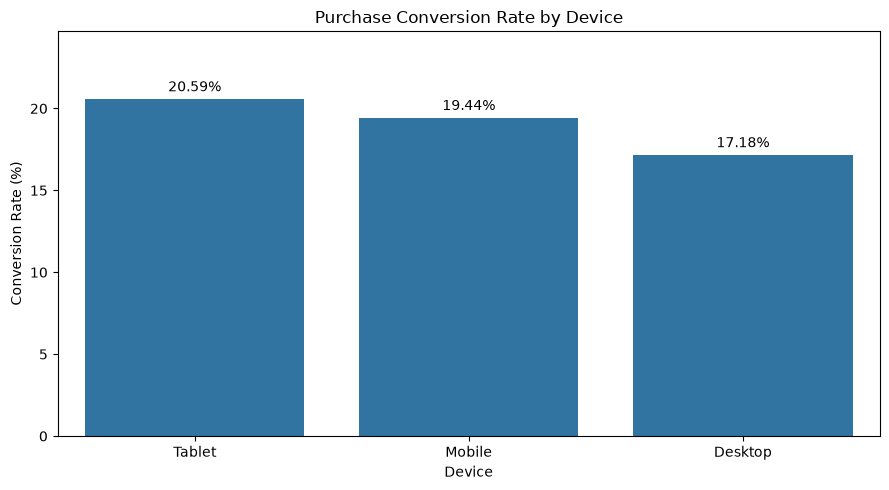

In [37]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=device_conversion,
    x="device",
    y="conversion_rate"
)

# Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Purchase Conversion Rate by Device")
plt.xlabel("Device")
plt.ylabel("Conversion Rate (%)")
plt.ylim(0, device_conversion["conversion_rate"].max() * 1.2)

plt.tight_layout()
plt.show()

Device vs Conversion Rate — Temuan Utama (Key Findings)

1. Tablet memiliki tingkat konversi (Conversion Rate) tertinggi, yaitu 20,59%. Namun, jumlah sampel yang relatif kecil, yaitu hanya 34 pengguna, membatasi keandalan hasil apabila dibandingkan secara langsung dengan perangkat lainnya.

2. Mobile memberikan kontribusi jumlah pembelian terbesar, yaitu 98 pembelian atau sekitar 65,33% dari total pembelian. Hal ini didukung oleh dominasi jumlah pengguna Mobile dibandingkan perangkat lainnya.

3. Desktop memiliki Conversion Rate terendah, yaitu 17,18%. Kondisi ini menunjukkan adanya potensi untuk melakukan investigasi lebih lanjut terhadap pengalaman pengguna (User Experience) dan faktor-faktor yang memengaruhi konversi pada perangkat Desktop.

Kesimpulan

Mobile menjadi perangkat paling penting berdasarkan volume pembelian (Purchase Volume) dan kontribusi pendapatan (Revenue Contribution).
Sementara itu, Tablet menunjukkan Conversion Rate tertinggi, tetapi jumlah sampel yang terbatas membuat hasil tersebut belum cukup kuat untuk menyimpulkan bahwa performanya lebih baik dibandingkan perangkat lainnya.

Oleh karena itu, diperlukan analisis lebih lanjut untuk mengevaluasi apakah terdapat perbedaan tingkat konversi yang signifikan antarperangkat.
Analisis ini dapat menjadi dasar untuk mengoptimalkan pengalaman pengguna (User Experience), meningkatkan efektivitas proses konversi, serta menentukan prioritas pengembangan berdasarkan karakteristik masing-masing perangkat.

## Multivariate Analysis

## Conversion Rate by Marketing Channel and Device

In [40]:
# Aggregate users and purchases by channel and device
channel_device = df_clean.groupby(
    ["channel", "device"]
).agg(
    total_users=("user_id", "nunique"),
    total_purchase=("purchase", "sum")
).reset_index()

# Calculate conversion rate
channel_device["conversion_rate"] = (
    channel_device["total_purchase"] /
    channel_device["total_users"] * 100
)

display(channel_device.round(2))

,channel,device,total_users,total_purchase,conversion_rate
0,Email,Desktop,38,6,15.79
1,Email,Mobile,83,13,15.66
2,Email,Tablet,4,1,25.00
3,Organic Search,Desktop,70,8,11.43
4,Organic Search,Mobile,124,22,17.74
5,Organic Search,Tablet,4,1,25.00
6,Paid Ads,Desktop,87,17,19.54
7,Paid Ads,Mobile,155,33,21.29
8,Paid Ads,Tablet,9,1,11.11
9,Referral,Desktop,25,7,28.00


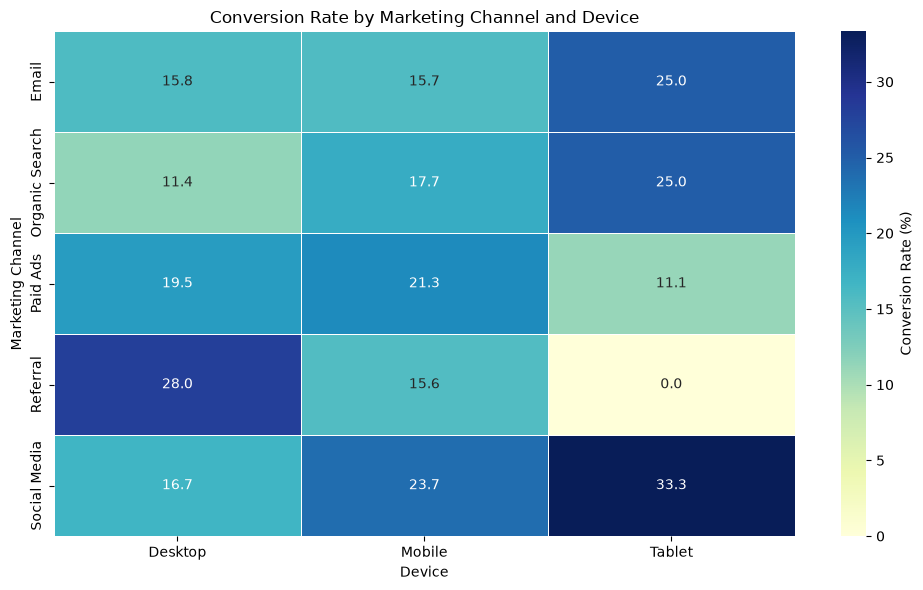

In [41]:
# Create pivot table
conversion_pivot = channel_device.pivot(
    index="channel",
    columns="device",
    values="conversion_rate"
)

# Visualize heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    conversion_pivot,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Conversion Rate (%)"}
)

plt.title("Conversion Rate by Marketing Channel and Device")
plt.xlabel("Device")
plt.ylabel("Marketing Channel")

plt.tight_layout()
plt.show()

Conversion Rate by Marketing Channel and Device — Key Findings

1. Social Media memiliki tingkat konversi (Conversion Rate) yang relatif tinggi pada perangkat Mobile (23,7%) dan Tablet (33,3%). Hal ini menunjukkan adanya potensi optimalisasi strategi pemasaran berdasarkan jenis perangkat (Device-Specific Optimization).

2. Referral mencatatkan Conversion Rate tertinggi pada perangkat Desktop (28,0%), mengungguli marketing channel lainnya dalam kategori perangkat yang sama. Hal ini mengindikasikan bahwa Referral memiliki potensi konversi yang baik pada pengguna Desktop.

3. Paid Ads menunjukkan performa konversi yang lebih tinggi pada perangkat Mobile (21,3%), dibandingkan Desktop (19,5%) dan Tablet (11,1%). Hal ini menunjukkan bahwa pengguna Mobile memiliki kecenderungan konversi yang lebih tinggi pada channel Paid Ads dalam dataset ini.

4. Conversion Rate menunjukkan variasi pada setiap kombinasi Marketing Channel dan Device. Hal ini mengindikasikan bahwa segmentasi berdasarkan perangkat dapat memberikan insight tambahan yang tidak terlihat apabila analisis hanya dilakukan pada tingkat marketing channel secara keseluruhan.

Kesimpulan

Efektivitas konversi pemasaran menunjukkan perbedaan antarsegmen perangkat dan marketing channel.
Social Media memiliki tingkat konversi yang relatif tinggi pada Mobile dan Tablet, Referral unggul pada Desktop, sementara Paid Ads menunjukkan performa terbaik pada Mobile dibandingkan perangkat lainnya.

Namun, jumlah sampel pada setiap kombinasi channel dan device perlu diperhatikan, terutama pada pengguna Tablet, sebelum menyimpulkan adanya perbedaan performa yang signifikan.

Oleh karena itu, diperlukan analisis lebih lanjut untuk mengidentifikasi kombinasi Marketing Channel dan Device yang paling potensial, sehingga strategi pemasaran, alokasi anggaran, dan optimalisasi pengalaman pengguna dapat dilakukan secara lebih efektif dan tepat sasaran.

In [42]:
# Aggregate revenue by channel and device
channel_device_revenue = df_clean.groupby(
    ["channel", "device"]
).agg(
    total_users=("user_id", "nunique"),
    total_revenue=("revenue", "sum"),
    total_purchase=("purchase", "sum")
).reset_index()

# Calculate revenue per user
channel_device_revenue["revenue_per_user"] = (
    channel_device_revenue["total_revenue"] /
    channel_device_revenue["total_users"]
)

display(channel_device_revenue.round(2))

,channel,device,total_users,total_revenue,total_purchase,revenue_per_user
0,Email,Desktop,38,1706020,6,44895.26
1,Email,Mobile,83,2989842,13,36022.19
2,Email,Tablet,4,198811,1,49702.75
3,Organic Search,Desktop,70,2370188,8,33859.83
4,Organic Search,Mobile,124,5198300,22,41921.77
5,Organic Search,Tablet,4,403986,1,100996.50
6,Paid Ads,Desktop,87,4695313,17,53969.11
7,Paid Ads,Mobile,155,8141618,33,52526.57
8,Paid Ads,Tablet,9,340327,1,37814.11
9,Referral,Desktop,25,2097327,7,83893.08


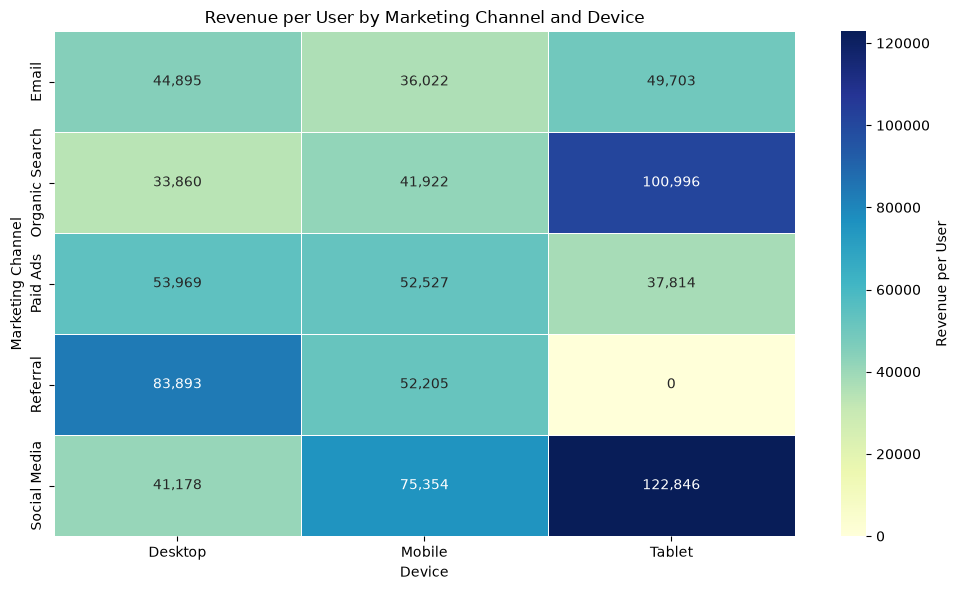

In [43]:
# Create pivot table
revenue_pivot = channel_device_revenue.pivot(
    index="channel",
    columns="device",
    values="revenue_per_user"
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    revenue_pivot,
    annot=True,
    fmt=",.0f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Revenue per User"}
)

plt.title("Revenue per User by Marketing Channel and Device")
plt.xlabel("Device")
plt.ylabel("Marketing Channel")

plt.tight_layout()
plt.show()

Revenue Performance by Marketing Channel and Device — Key Findings

1. Social Media Tablet menghasilkan pendapatan rata-rata per pengguna (Revenue per User) tertinggi, yaitu 122.846, dengan tingkat konversi (Conversion Rate) sebesar 33,3%. Namun, jumlah sampel yang relatif kecil, yaitu hanya 12 pengguna, membatasi keandalan hasil analisis tersebut.

2. Social Media Mobile menunjukkan performa yang kuat dengan menghasilkan total pendapatan sebesar 7,31 juta, Revenue per User sebesar 75.355, dan Conversion Rate sebesar 23,71%. Hal ini mengindikasikan bahwa segmen Social Media Mobile memiliki potensi yang baik dalam menghasilkan pendapatan dan mendorong konversi pengguna.

3. Referral Desktop mencatatkan Revenue per User sebesar 83.893 dengan Conversion Rate sebesar 28%. Hasil ini menunjukkan adanya potensi untuk melakukan investigasi lebih lanjut terhadap efektivitas channel Referral pada pengguna Desktop.

4. Paid Ads Mobile memberikan kontribusi total pendapatan tertinggi di antara seluruh kombinasi Marketing Channel dan Device, yaitu sebesar 8,14 juta, didukung oleh 155 pengguna. Hal ini menunjukkan bahwa Paid Ads Mobile memiliki peran penting dalam menghasilkan pendapatan secara keseluruhan.

Kesimpulan

Social Media Mobile menjadi salah satu segmen yang paling potensial untuk dikembangkan karena menunjukkan kombinasi yang baik antara total pendapatan (Revenue), pendapatan per pengguna (Revenue per User), tingkat konversi (Conversion Rate), dan jumlah sampel pengguna.

Sementara itu, Paid Ads Mobile tetap menjadi kontributor pendapatan terbesar, sedangkan Social Media Tablet dan Referral Desktop menunjukkan efisiensi monetisasi yang menarik berdasarkan Revenue per User.

Namun, data biaya pemasaran (Marketing Cost) dan validasi tambahan masih diperlukan sebelum menentukan keputusan alokasi anggaran pemasaran.
Oleh karena itu, analisis lanjutan terhadap Customer Acquisition Cost (CAC), Return on Ad Spend (ROAS), dan profitabilitas masing-masing segmen diperlukan untuk mengidentifikasi peluang pertumbuhan yang paling efektif dan berkelanjutan.

## Marketing & Growth Analysis

### Monthly Growth Analysis

In [46]:
# Aggregate monthly performance
monthly_growth = df_clean.groupby("year_month").agg(
    total_users=("user_id", "nunique"),
    total_purchase=("purchase", "sum"),
    total_revenue=("revenue", "sum"),
    total_ad_cost=("ad_cost", "sum")
).reset_index()

# Calculate monthly growth rates
monthly_growth["user_growth_pct"] = (
    monthly_growth["total_users"].pct_change() * 100
)

monthly_growth["revenue_growth_pct"] = (
    monthly_growth["total_revenue"].pct_change() * 100
)

# Calculate conversion rate
monthly_growth["conversion_rate"] = (
    monthly_growth["total_purchase"] /
    monthly_growth["total_users"] * 100
)

display(monthly_growth.round(2))

,year_month,total_users,total_purchase,total_revenue,total_ad_cost,user_growth_pct,revenue_growth_pct,conversion_rate
0,2025-01,403,76,21128825,5516531,NaN,NaN,18.86
1,2025-02,384,71,19217017,5246169,-4.71,-9.05,18.49
2,2025-03,13,3,658063,186207,-96.61,-96.58,23.08


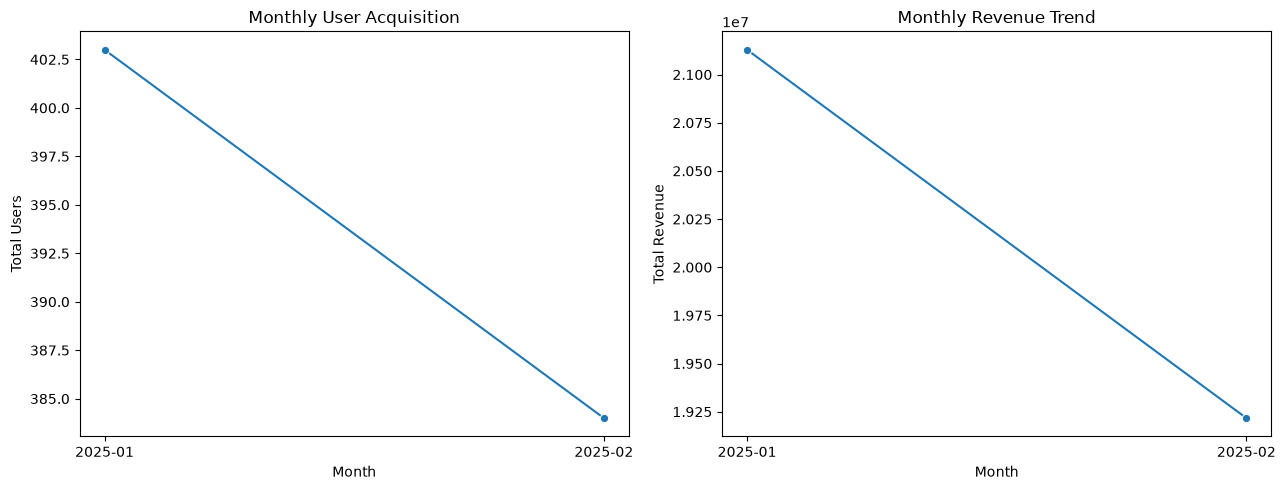

In [47]:
# Filter complete months
monthly_complete = monthly_growth[
    monthly_growth["year_month"].isin(["2025-01", "2025-02"])
].copy()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.lineplot(
    data=monthly_complete,
    x="year_month",
    y="total_users",
    marker="o",
    ax=axes[0]
)

axes[0].set_title("Monthly User Acquisition")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Total Users")

sns.lineplot(
    data=monthly_complete,
    x="year_month",
    y="total_revenue",
    marker="o",
    ax=axes[1]
)

axes[1].set_title("Monthly Revenue Trend")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Total Revenue")

plt.tight_layout()
plt.show()

Monthly Growth Analysis — Key Findings

1. User Acquisition mengalami penurunan sebesar 4,71%, dari 403 pengguna pada Januari menjadi 384 pengguna pada Februari 2025. Hal ini menunjukkan adanya penurunan jumlah pengguna yang berhasil diakuisisi.

2. Total Revenue mengalami penurunan sebesar 9,05%, lebih besar dibandingkan penurunan jumlah pengguna. Hal ini mengindikasikan adanya penurunan kemampuan menghasilkan pendapatan rata-rata per pengguna (Revenue per User).

3. Purchase Conversion Rate menunjukkan kondisi yang relatif stabil, dengan sedikit penurunan dari 18,86% menjadi 18,49%. Hal ini menunjukkan bahwa proporsi pengguna yang melakukan pembelian tidak mengalami perubahan yang signifikan secara deskriptif.

4. Advertising Cost mengalami penurunan sebesar 4,88%. Namun, penurunan biaya iklan tersebut lebih kecil dibandingkan penurunan Revenue. Kondisi ini mengindikasikan adanya potensi penurunan efisiensi pendapatan terhadap biaya iklan secara agregat.

Kesimpulan

Pada Februari 2025, terjadi penurunan jumlah pengguna (User Acquisition), jumlah pembelian (Purchases), dan total pendapatan (Revenue) dibandingkan Januari 2025.

Penurunan Revenue yang lebih besar dibandingkan User Acquisition menunjukkan bahwa penurunan performa bisnis tidak hanya dipengaruhi oleh berkurangnya jumlah pengguna, tetapi juga berpotensi berkaitan dengan melemahnya monetisasi per pengguna.

Oleh karena itu, diperlukan analisis lebih lanjut terhadap Revenue per User, Average Order Value (AOV), Conversion Rate, dan efektivitas Marketing Channel untuk mengidentifikasi faktor utama penurunan pendapatan.

Strategi pertumbuhan sebaiknya tidak hanya berfokus pada peningkatan akuisisi pengguna, tetapi juga pada optimalisasi konversi dan peningkatan pendapatan per pengguna agar pertumbuhan bisnis menjadi lebih efektif dan berkelanjutan.

Catatan: Data Maret 2025 tidak disertakan dalam perbandingan pertumbuhan bulanan (Month-over-Month/MoM) karena dataset hanya mencakup tanggal 1 Maret 2025, sehingga belum merepresentasikan performa satu bulan penuh.

### Marketing Channel Effectiveness Analysis

In [48]:
# Aggregate marketing channel performance
channel_kpi = df_clean.groupby("channel").agg(
    total_users=("user_id", "nunique"),
    total_clicks=("clicks", "sum"),
    total_impressions=("impressions", "sum"),
    total_purchase=("purchase", "sum"),
    total_revenue=("revenue", "sum"),
    total_ad_cost=("ad_cost", "sum")
).reset_index()

# Calculate marketing KPIs
channel_kpi["CTR (%)"] = (
    channel_kpi["total_clicks"] /
    channel_kpi["total_impressions"] * 100
)

channel_kpi["CPC"] = (
    channel_kpi["total_ad_cost"] /
    channel_kpi["total_clicks"].replace(0, np.nan)
)

channel_kpi["CPM"] = (
    channel_kpi["total_ad_cost"] /
    channel_kpi["total_impressions"].replace(0, np.nan) * 1000
)

channel_kpi["CVR (%)"] = (
    channel_kpi["total_purchase"] /
    channel_kpi["total_users"] * 100
)

channel_kpi["CAC Proxy"] = (
    channel_kpi["total_ad_cost"] /
    channel_kpi["total_purchase"].replace(0, np.nan)
)

channel_kpi["ROAS"] = (
    channel_kpi["total_revenue"] /
    channel_kpi["total_ad_cost"].replace(0, np.nan)
)

channel_kpi["Revenue per User"] = (
    channel_kpi["total_revenue"] /
    channel_kpi["total_users"]
)

# Cost efficiency metrics only apply to channels
# with recorded advertising expenditure
cost_metrics = ["CPC", "CPM", "CAC Proxy"]
channel_kpi.loc[
    channel_kpi["total_ad_cost"] == 0,
    cost_metrics
] = np.nan

display(channel_kpi.round(2))

,channel,total_users,total_clicks,total_impressions,total_purchase,total_revenue,total_ad_cost,CTR (%),CPC,CPM,CVR (%),CAC Proxy,ROAS,Revenue per User
0,Email,125,2990,71912,20,4894673,0,4.16,NaN,NaN,16.00,NaN,NaN,39157.38
1,Organic Search,198,5008,109047,31,7972474,0,4.59,NaN,NaN,15.66,NaN,NaN,40265.02
2,Paid Ads,251,5945,137844,51,13177258,10948907,4.31,1841.7,79429.7,20.32,214684.45,1.2,52499.04
3,Referral,75,1665,39040,14,4446539,0,4.26,NaN,NaN,18.67,NaN,NaN,59287.19
4,Social Media,151,3885,84857,34,10512961,0,4.58,NaN,NaN,22.52,NaN,NaN,69622.26


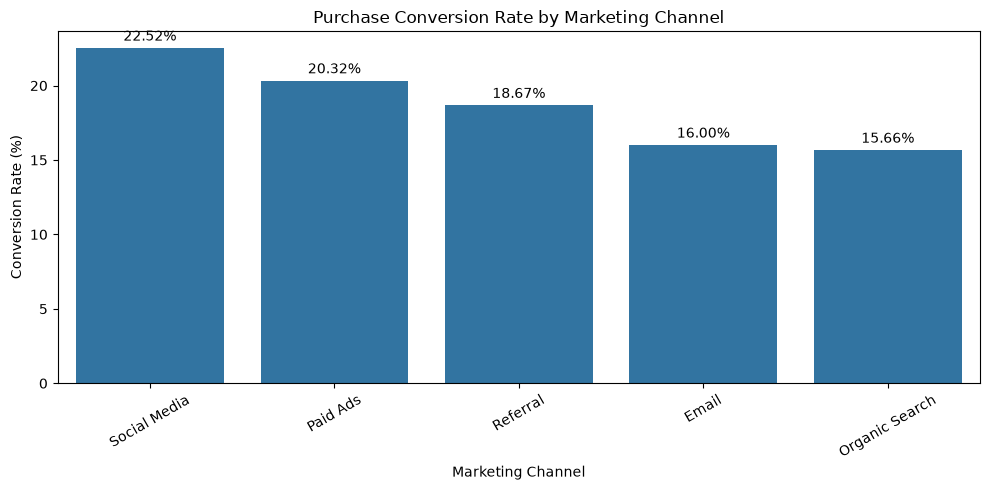

In [49]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=channel_kpi.sort_values("CVR (%)", ascending=False),
    x="channel",
    y="CVR (%)"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Purchase Conversion Rate by Marketing Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

Marketing Channel Effectiveness — Key Findings

1. Social Media memiliki tingkat konversi pembelian (Purchase Conversion Rate) tertinggi, yaitu 22,52%, serta pendapatan rata-rata per pengguna (Revenue per User) sebesar 69.622. Hal ini menunjukkan bahwa Social Media memiliki performa monetisasi pengguna yang relatif kuat dalam dataset.

2. Organic Search mencatatkan Click Through Rate (CTR) tertinggi, yaitu 4,59%, tetapi memiliki Purchase Conversion Rate terendah sebesar 15,66%. Hal ini menunjukkan bahwa tingkat interaksi pengguna terhadap iklan atau konten tidak selalu sejalan dengan tingkat konversi pembelian.

3. Paid Ads menghasilkan total pendapatan tertinggi, yaitu 13,18 juta, tetapi memiliki Return on Ad Spend (ROAS) sebesar 1,20x. Hal ini menunjukkan bahwa setiap 1 satuan biaya iklan menghasilkan 1,20 satuan pendapatan, sehingga selisih pendapatan terhadap biaya iklan relatif terbatas sebelum memperhitungkan biaya operasional dan biaya lainnya.

4. Paid Ads memiliki Cost per Click (CPC) sebesar 1.841,70 dan estimasi Customer Acquisition Cost (CAC Proxy) sebesar 214.684. Hal ini menunjukkan pentingnya mengevaluasi biaya akuisisi pelanggan bersamaan dengan pendapatan yang dihasilkan untuk menilai efektivitas strategi pemasaran.

Kesimpulan

Paid Ads menjadi marketing channel dengan kontribusi total pendapatan terbesar, sementara Social Media menunjukkan performa yang lebih baik berdasarkan Conversion Rate dan Revenue per User.

Di sisi lain, tingginya CTR pada Organic Search tidak selalu menghasilkan tingkat konversi pembelian yang tinggi. Sementara itu, ROAS Paid Ads yang hanya mencapai 1,20x mengindikasikan bahwa efisiensi pengeluaran iklan masih perlu dievaluasi lebih lanjut.

Oleh karena itu, optimalisasi strategi pemasaran perlu mempertimbangkan kualitas konversi pengguna, biaya akuisisi pelanggan (CAC), efisiensi pengeluaran iklan (ROAS), dan profitabilitas setiap marketing channel.

Analisis lanjutan diperlukan sebelum melakukan perubahan alokasi anggaran pemasaran, sehingga keputusan dapat didasarkan pada keseimbangan antara pertumbuhan pengguna, peningkatan pendapatan, dan efisiensi biaya pemasaran.

### Conversion Funnel Analysis

In [52]:
# Calculate funnel stages
total_users = df_clean["user_id"].nunique()
total_cart = df_clean["add_to_cart"].sum()
total_purchase = df_clean["purchase"].sum()

funnel = pd.DataFrame({
    "stage": ["Total Users", "Add to Cart", "Purchase"],
    "users": [total_users, total_cart, total_purchase]
})

# Conversion from previous stage
funnel["conversion_rate_pct"] = (
    funnel["users"] /
    funnel["users"].shift(1) * 100
)

# Drop-off from previous stage
funnel["dropoff_rate_pct"] = (
    100 - funnel["conversion_rate_pct"]
)

display(funnel.round(2))

,stage,users,conversion_rate_pct,dropoff_rate_pct
0,Total Users,800,NaN,NaN
1,Add to Cart,329,41.12,58.88
2,Purchase,150,45.59,54.41


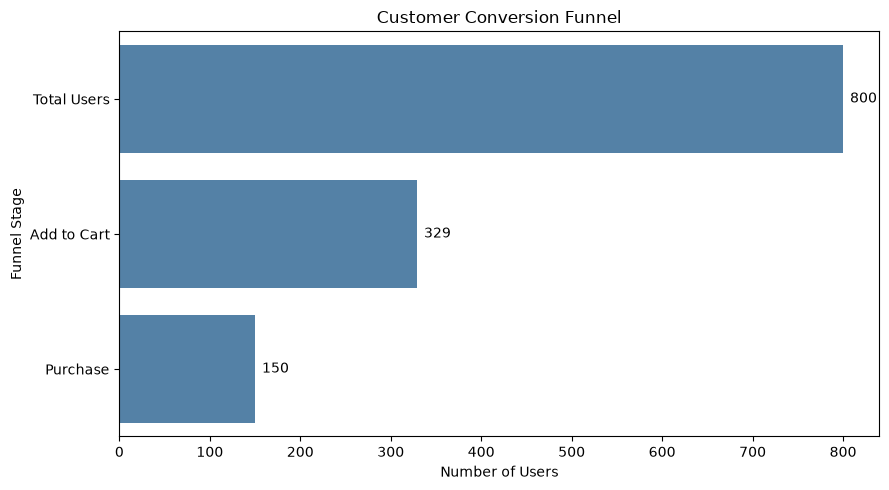

In [53]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=funnel,
    x="users",
    y="stage",
    color="steelblue"
)

for container in ax.containers:
    ax.bar_label(container, padding=5)

plt.title("Customer Conversion Funnel")
plt.xlabel("Number of Users")
plt.ylabel("Funnel Stage")

plt.tight_layout()
plt.show()

Conversion Funnel Analysis — Key Findings

1. Add-to-Cart Rate (41,12%): Dari total 800 pengguna, sebanyak 329 pengguna mencapai tahap penambahan produk ke keranjang (Add to Cart), sementara 58,88% pengguna tidak mencapai tahap tersebut.

2. Cart-to-Purchase Conversion (45,59%): Dari 329 pengguna yang telah menambahkan produk ke keranjang, sebanyak 150 pengguna berhasil menyelesaikan pembelian (Purchase).

3. Cart-to-Purchase Drop-off (54,41%): Lebih dari setengah pengguna yang telah menambahkan produk ke keranjang tidak melanjutkan hingga tahap pembelian dalam periode pengamatan. Hal ini menunjukkan adanya potensi hambatan dalam proses konversi dari keranjang menuju transaksi.

4. Overall Purchase Conversion Rate (18,75%): Dari total 800 pengguna, hanya 150 pengguna yang berhasil melakukan pembelian. Hal ini menunjukkan bahwa sebagian besar pengguna belum berhasil dikonversi menjadi pembeli.

Kesimpulan

Analisis Conversion Funnel menunjukkan adanya penurunan jumlah pengguna (User Drop-off) yang cukup besar, baik sebelum tahap Add to Cart maupun pada proses konversi dari Add to Cart menuju Purchase.

Tingginya tingkat drop-off tersebut mengindikasikan adanya peluang untuk meningkatkan efektivitas proses konversi, khususnya melalui optimalisasi penemuan produk (Product Discovery) dan evaluasi potensi hambatan pada proses checkout (Checkout Friction).

Oleh karena itu, diperlukan analisis perilaku pengguna lebih lanjut untuk mengidentifikasi faktor-faktor yang menyebabkan pengguna tidak melanjutkan proses pembelian.

Hasil analisis ini dapat menjadi dasar dalam menyusun strategi Conversion Rate Optimization (CRO), dengan tujuan mengurangi tingkat drop-off, meningkatkan jumlah transaksi, serta memaksimalkan potensi pendapatan dari pengguna yang sudah berhasil diakuisisi.

### Customer Retention Analysis

In [55]:
# Calculate retention metrics
total_users = df_clean["user_id"].nunique()
total_buyers = df_clean["purchase"].sum()
repeat_buyers = df_clean["repeat_purchase"].sum()

retention_summary = pd.DataFrame({
    "Metric": [
        "Total Users",
        "Purchasing Users",
        "Repeat Purchasing Users",
        "Repeat Purchase Rate (All Users) %",
        "Repeat Purchase Rate (Buyers) %"
    ],
    "Value": [
        total_users,
        total_buyers,
        repeat_buyers,
        repeat_buyers / total_users * 100,
        repeat_buyers / total_buyers * 100
    ]
})

display(retention_summary.round(2))

,Metric,Value
0,Total Users,800.0
1,Purchasing Users,150.0
2,Repeat Purchasing Users,48.0
3,Repeat Purchase Rate (All Users) %,6.0
4,Repeat Purchase Rate (Buyers) %,32.0


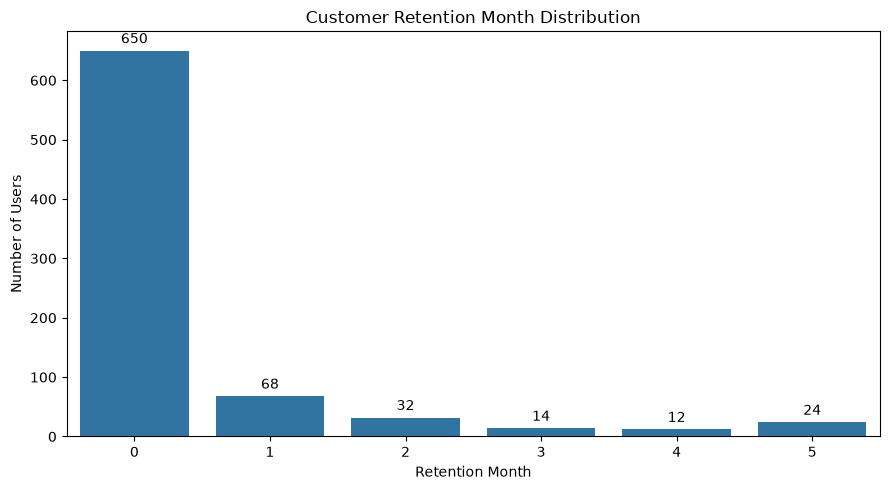

In [56]:
plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=df_clean,
    x="retention_month",
    order=sorted(df_clean["retention_month"].unique())
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title("Customer Retention Month Distribution")
plt.xlabel("Retention Month")
plt.ylabel("Number of Users")

plt.tight_layout()
plt.show()

Customer Retention Analysis — Temuan Utama (Key Findings)

1. Repeat Purchase Rate: Dari total 150 pengguna yang melakukan pembelian, sebanyak 48 pengguna (32%) tercatat melakukan pembelian berulang (Repeat Purchase), sementara 102 pengguna tidak melakukan pembelian berulang.

2. Retention Month Distribution: Sebagian besar pengguna, yaitu 81,25%, memiliki nilai Retention Month sebesar nol, sementara 18,75% pengguna memiliki nilai Retention Month positif. Hal ini menunjukkan bahwa mayoritas pengguna belum memiliki durasi retensi yang tercatat lebih dari nol bulan.

3. Retention Concentration: Di antara pengguna dengan nilai Retention Month positif, sebanyak 68 pengguna tercatat pada bulan pertama (Month 1), sedangkan kelompok pengguna yang lebih kecil tersebar pada bulan ke-2 hingga ke-5. Hal ini menunjukkan bahwa distribusi nilai retensi terkonsentrasi pada bulan pertama.

4. Data Limitation: Dataset belum menyediakan informasi aktivitas pembelian historis (Longitudinal Purchase Data) yang memadai untuk menghitung tingkat retensi berdasarkan kelompok pelanggan (Cohort Retention) maupun tingkat kehilangan pelanggan (Churn Rate) secara akurat.

Kesimpulan

Analisis menunjukkan bahwa 32% dari pengguna yang melakukan pembelian tercatat memiliki aktivitas pembelian berulang (Repeat Purchase). Hal ini mengindikasikan adanya peluang untuk mengevaluasi dan meningkatkan loyalitas pelanggan (Customer Loyalty) serta perilaku pembelian berulang (Repeat 
Purchasing Behavior).

Namun, nilai Retention Month masih memerlukan validasi lebih lanjut sebelum dapat diinterpretasikan sebagai durasi retensi pelanggan yang sebenarnya.
Oleh karena itu, diperlukan analisis tambahan menggunakan riwayat transaksi pelanggan, frekuensi pembelian, dan Cohort Analysis untuk memahami pola retensi secara lebih akurat.

Hasil analisis tersebut dapat menjadi dasar dalam mengembangkan strategi Customer Retention dan Loyalty Program untuk meningkatkan pembelian berulang, memperpanjang hubungan pelanggan dengan bisnis, serta mengoptimalkan Customer Lifetime Value (CLV).

In [57]:
# Validate retention month against purchase status
retention_validation = pd.crosstab(
    df_clean["purchase"],
    df_clean["retention_month"] > 0,
    margins=True
)

display(retention_validation)

retention_month,False,True,All
purchase,,,
0,650,0,650
1,0,150,150
All,650,150,800


### Assumption-Based Cohort Retention & Churn Analysis

In [58]:
# Filter purchasing users
cohort_df = df_clean[df_clean["purchase"] == 1].copy()

# Define cohort month
cohort_df["cohort_month"] = (
    cohort_df["first_visit_date"]
    .dt.to_period("M")
    .astype(str)
)

# Assumption:
# retention_month represents the last active month
# Users remain active from month 0 until retention_month

display(cohort_df[
    ["user_id", "cohort_month", "retention_month"]
].head())

,user_id,cohort_month,retention_month
0,1,2025-02,2
5,6,2025-01,2
6,7,2025-01,4
7,8,2025-02,2
11,12,2025-01,4


In [59]:
# Create simulated monthly activity records
cohort_records = []

for _, row in cohort_df.iterrows():
    for month in range(row["retention_month"] + 1):
        cohort_records.append({
            "user_id": row["user_id"],
            "cohort_month": row["cohort_month"],
            "month_index": month
        })

cohort_activity = pd.DataFrame(cohort_records)

# Calculate cohort size
cohort_size = (
    cohort_df.groupby("cohort_month")["user_id"]
    .nunique()
)

# Calculate active users by cohort and month
cohort_counts = cohort_activity.pivot_table(
    index="cohort_month",
    columns="month_index",
    values="user_id",
    aggfunc="nunique",
    fill_value=0
)

# Calculate retention rate
cohort_retention = (
    cohort_counts.div(cohort_size, axis=0) * 100
)

display(cohort_retention.round(2))

month_index,0,1,2,3,4,5
cohort_month,,,,,,
2025-01,100.0,100.0,61.84,35.53,25.00,13.16
2025-02,100.0,100.0,47.89,30.99,22.54,19.72
2025-03,100.0,100.0,33.33,33.33,33.33,0.00


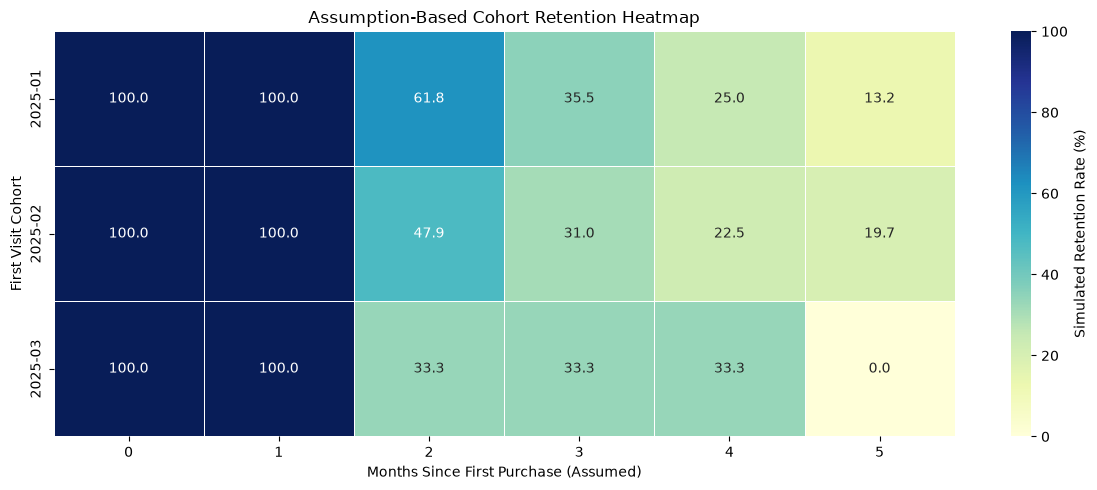

In [60]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    cohort_retention,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Simulated Retention Rate (%)"}
)

plt.title("Assumption-Based Cohort Retention Heatmap")
plt.xlabel("Months Since First Purchase (Assumed)")
plt.ylabel("First Visit Cohort")

plt.tight_layout()
plt.show()

Cohort Retention Analysis — Key Findings

1. Overall Retention Trend: Seluruh cohort menunjukkan tingkat retensi berdasarkan model asumsi (Modeled Retention) sebesar 100% pada Month 0 dan Month 1. Tingkat retensi mulai mengalami penurunan pada Month 2, yang mengindikasikan berkurangnya jumlah pelanggan yang diasumsikan tetap aktif seiring berjalannya waktu.

2. January Cohort: Cohort Januari 2025 menunjukkan tingkat retensi tertinggi pada Month 2 sebesar 61,8%, dibandingkan Februari (47,9%) dan Maret (33,3%). Namun, tingkat retensi tersebut secara bertahap mengalami penurunan hingga mencapai 13,2% pada Month 5.

3. February Cohort: Cohort Februari 2025 mencatatkan tingkat retensi tertinggi pada Month 5 sebesar 19,7%, melampaui Januari (13,2%). Hal ini mengindikasikan bahwa pelanggan yang diakuisisi pada Februari memiliki tingkat retensi jangka panjang yang lebih kuat berdasarkan model asumsi yang digunakan.

4. March Cohort: Cohort Maret 2025 mempertahankan tingkat retensi sebesar 33,3% dari Month 2 hingga Month 4, sebelum mengalami penurunan menjadi 0% pada Month 5. Namun, jumlah sampel cohort yang relatif kecil membatasi keandalan hasil apabila dibandingkan dengan cohort lainnya.

5. Data Limitations: Analisis ini menggunakan asumsi bahwa variabel retention_month merepresentasikan durasi retensi pelanggan dan bahwa pelanggan tetap aktif secara berkelanjutan selama periode tersebut (Continuous Retention Assumption). Oleh karena itu, hasil analisis merupakan estimasi berdasarkan model asumsi, bukan tingkat retensi bulanan yang diamati secara langsung melalui aktivitas transaksi pelanggan.

Kesimpulan

Analisis Cohort Retention menunjukkan bahwa cohort Januari memiliki tingkat retensi awal yang lebih kuat, khususnya pada Month 2, sementara cohort Februari menunjukkan tingkat retensi jangka panjang tertinggi pada Month 5.

Perbedaan ini mengindikasikan adanya potensi variasi pola keterlibatan pelanggan (Customer Engagement) berdasarkan periode akuisisi.
Namun, hasil analisis belum dapat dijadikan kesimpulan definitif mengenai performa retensi pelanggan, mengingat perhitungan masih menggunakan asumsi durasi retensi dan belum didukung oleh riwayat transaksi bulanan yang lengkap.

Oleh karena itu, diperlukan validasi lebih lanjut menggunakan data transaksi aktual per bulan, tanggal akuisisi pelanggan, serta periode observasi yang terverifikasi untuk memastikan keakuratan pola retensi.

Hasil analisis yang telah tervalidasi nantinya dapat digunakan untuk mengembangkan strategi Customer Retention, Repeat Purchase Optimization, dan Customer Lifecycle Management guna meningkatkan loyalitas pelanggan serta mempertahankan pertumbuhan pendapatan dalam jangka panjang.

### Marketing Efficiency Analysis

In [69]:
# Filter Paid Ads
paid_ads = df_clean[df_clean["channel"] == "Paid Ads"].copy()

# Calculate marketing metrics
total_users = paid_ads["user_id"].nunique()
purchasing_users = paid_ads["purchase"].sum()

total_revenue = paid_ads["revenue"].sum()
total_ad_cost = paid_ads["ad_cost"].sum()

conversion_rate = purchasing_users / total_users * 100
roas = total_revenue / total_ad_cost
cost_per_purchaser = total_ad_cost / purchasing_users
revenue_per_user = total_revenue / total_users

# Create summary table
marketing_efficiency = pd.DataFrame({
    "Metric": [
        "Total Users",
        "Purchasing Users",
        "Total Revenue",
        "Total Ad Cost",
        "Conversion Rate (%)",
        "ROAS",
        "Cost per Purchasing User",
        "Revenue per User"
    ],
    "Value": [
        total_users,
        purchasing_users,
        total_revenue,
        total_ad_cost,
        conversion_rate,
        roas,
        cost_per_purchaser,
        revenue_per_user
    ]
})

display(marketing_efficiency.round(2))

,Metric,Value
0,Total Users,251.00
1,Purchasing Users,51.00
2,Total Revenue,13177258.00
3,Total Ad Cost,10948907.00
4,Conversion Rate (%),20.32
5,ROAS,1.20
6,Cost per Purchasing User,214684.45
7,Revenue per User,52499.04


In [70]:
# Filter Paid Ads
paid_ads = df_clean[df_clean["channel"] == "Paid Ads"].copy()

# Calculate marketing metrics
total_users = paid_ads["user_id"].nunique()
purchasing_users = paid_ads["purchase"].sum()

total_revenue = paid_ads["revenue"].sum()
total_ad_cost = paid_ads["ad_cost"].sum()

conversion_rate = purchasing_users / total_users * 100
roas = total_revenue / total_ad_cost
cost_per_purchaser = total_ad_cost / purchasing_users
revenue_per_user = total_revenue / total_users

# Create summary table
marketing_efficiency = pd.DataFrame({
    "Metric": [
        "Total Users",
        "Purchasing Users",
        "Total Revenue",
        "Total Ad Cost",
        "Conversion Rate (%)",
        "ROAS",
        "Cost per Purchasing User",
        "Revenue per User"
    ],
    "Value": [
        total_users,
        purchasing_users,
        total_revenue,
        total_ad_cost,
        conversion_rate,
        roas,
        cost_per_purchaser,
        revenue_per_user
    ]
})

display(marketing_efficiency.round(2))

,Metric,Value
0,Total Users,251.00
1,Purchasing Users,51.00
2,Total Revenue,13177258.00
3,Total Ad Cost,10948907.00
4,Conversion Rate (%),20.32
5,ROAS,1.20
6,Cost per Purchasing User,214684.45
7,Revenue per User,52499.04


Marketing Efficiency Analysis — Key Findings

1. Paid Ads Performance: Paid Ads berhasil menjangkau 251 pengguna, dengan 51 pengguna melakukan pembelian, sehingga menghasilkan tingkat konversi (Conversion Rate) sebesar 20,32%. Hal ini menunjukkan kemampuan Paid Ads dalam menghasilkan konversi dari pengguna yang berhasil diakuisisi.

2. Revenue vs Advertising Cost: Paid Ads menghasilkan total pendapatan (Revenue) sebesar 13.177.258, dengan total biaya iklan (Advertising Cost) sebesar 10.948.907, sehingga terdapat selisih positif antara pendapatan dan biaya iklan sebesar 2.228.351.

3. Return on Ad Spend (ROAS): Nilai ROAS sebesar 1,20x menunjukkan bahwa setiap 1 satuan biaya iklan menghasilkan sekitar 1,20 satuan pendapatan. Namun, kondisi ini belum tentu menunjukkan profitabilitas karena perhitungan belum memperhitungkan biaya produk (Cost of Goods Sold/COGS) maupun biaya operasional lainnya.

4. Customer Acquisition Cost Proxy: Estimasi biaya per pengguna yang melakukan pembelian mencapai 214.684,45, jauh lebih tinggi dibandingkan pendapatan rata-rata per pengguna (Revenue per User) sebesar 52.499,04. Namun, kedua metrik tersebut menggunakan dasar perhitungan (denominator) yang berbeda, sehingga tidak dapat dibandingkan secara langsung untuk menyimpulkan adanya kerugian pada tingkat pelanggan.

5. Marketing Efficiency Opportunity: Nilai ROAS yang relatif rendah menunjukkan adanya peluang untuk meningkatkan efisiensi pengeluaran iklan melalui optimalisasi target audiens (Audience Targeting), peningkatan performa kampanye (Campaign Optimization), serta akuisisi pelanggan dengan nilai transaksi yang lebih tinggi (Higher-Value Customer Acquisition).

Kesimpulan

Paid Ads berhasil menghasilkan konversi dan total pendapatan yang lebih besar dibandingkan biaya iklan yang tercatat, dengan selisih positif sebesar 2.228.351.

Namun, ROAS sebesar 1,20x menunjukkan bahwa ruang untuk menutupi biaya bisnis lainnya masih relatif terbatas, terutama setelah mempertimbangkan biaya produk, operasional, dan pengeluaran tambahan yang belum termasuk dalam analisis.

Oleh karena itu, strategi pemasaran perlu memprioritaskan peningkatan kualitas konversi (Conversion Quality), efisiensi biaya akuisisi pelanggan (Customer Acquisition Cost), serta peningkatan nilai pelanggan (Customer Value) sebelum melakukan peningkatan investasi iklan.

Optimalisasi tersebut dapat membantu meningkatkan efektivitas pengeluaran pemasaran, memperbaiki potensi profitabilitas, serta mendukung pertumbuhan bisnis yang lebih berkelanjutan.

### Export Clean Dataset for Power BI

In [72]:
# Export cleaned dataset
df_clean.to_csv(
    "marketing_growth_clean.csv",
    index=False
)

print("Clean dataset exported successfully!")
print("Dataset shape:", df_clean.shape)

Clean dataset exported successfully!
Dataset shape: (800, 21)


In [73]:
# Convert cohort retention matrix to long format
cohort_export = (
    cohort_retention
    .reset_index()
    .melt(
        id_vars="cohort_month",
        var_name="month_index",
        value_name="retention_rate_pct"
    )
)

# Rename columns for Power BI
cohort_export["month_index"] = (
    cohort_export["month_index"].astype(int)
)

cohort_export["retention_rate_pct"] = (
    cohort_export["retention_rate_pct"].round(2)
)

display(cohort_export.head(10))

# Export
cohort_export.to_csv(
    "cohort_retention.csv",
    index=False
)

,cohort_month,month_index,retention_rate_pct
0,2025-01,0,100.00
1,2025-02,0,100.00
2,2025-03,0,100.00
3,2025-01,1,100.00
4,2025-02,1,100.00
5,2025-03,1,100.00
6,2025-01,2,61.84
7,2025-02,2,47.89
8,2025-03,2,33.33
9,2025-01,3,35.53


In [75]:
# Aggregate marketing performance by channel
channel_export = (
    df_clean.groupby("channel")
    .agg(
        total_users=("user_id", "nunique"),
        total_purchases=("purchase", "sum"),
        total_revenue=("revenue", "sum"),
        total_ad_cost=("ad_cost", "sum"),
        total_clicks=("clicks", "sum"),
        total_impressions=("impressions", "sum")
    )
    .reset_index()
)

# Calculate KPIs
channel_export["conversion_rate_pct"] = (
    channel_export["total_purchases"] /
    channel_export["total_users"] * 100
)

channel_export["ctr_pct"] = (
    channel_export["total_clicks"] /
    channel_export["total_impressions"] * 100
)

channel_export["revenue_per_user"] = (
    channel_export["total_revenue"] /
    channel_export["total_users"]
)

# ROAS only where advertising cost is recorded
channel_export["roas"] = np.where(
    channel_export["total_ad_cost"] > 0,
    channel_export["total_revenue"] /
    channel_export["total_ad_cost"].replace(0, np.nan),
    np.nan
)

display(channel_export.round(2))

# Export
channel_export.to_csv(
    "marketing_channel_summary.csv",
    index=False
)

,channel,total_users,total_purchases,total_revenue,total_ad_cost,total_clicks,total_impressions,conversion_rate_pct,ctr_pct,revenue_per_user,roas
0,Email,125,20,4894673,0,2990,71912,16.00,4.16,39157.38,NaN
1,Organic Search,198,31,7972474,0,5008,109047,15.66,4.59,40265.02,NaN
2,Paid Ads,251,51,13177258,10948907,5945,137844,20.32,4.31,52499.04,1.2
3,Referral,75,14,4446539,0,1665,39040,18.67,4.26,59287.19,NaN
4,Social Media,151,34,10512961,0,3885,84857,22.52,4.58,69622.26,NaN


In [76]:
import os

files = [
    "marketing_growth_clean.csv",
    "cohort_retention.csv",
    "marketing_channel_summary.csv"
]

for file in files:
    print(
        file,
        "—",
        "Exported" if os.path.exists(file) else "Not Found"
    )

marketing_growth_clean.csv — Exported
cohort_retention.csv — Exported
marketing_channel_summary.csv — Exported
